In [ ]:
!pip install transformers[torch] datasets evaluate sacrebleu accelerate seaborn matplotlib jiwer -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 74.6 MB/s eta 0:00:00


In [ ]:
import torch
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset, DatasetDict
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    EarlyStoppingCallback
)
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Define Paths
# Path to your NEW dataset (Upload this to Drive or Colab first)
dataset_file = "/content/drive/MyDrive/nllb_multilingual_imperative_dataset.json"

# Path to the PREVIOUSLY TRAINED model (from the Word Training step)
# We try to load this first. If not found, we fall back to the base NLLB model.
pretrained_model_path = "/content/drive/MyDrive/Final_NLLB_interrogative_Model"
output_model_path = "/content/drive/MyDrive/Final_NLLB_imperative_Model"

print(f"📂 Dataset: {dataset_file}")
print(f"🤖 Loading Model from: {pretrained_model_path}")

📂 Dataset: /content/drive/MyDrive/nllb_multilingual_imperative_dataset.json
🤖 Loading Model from: /content/drive/MyDrive/Final_NLLB_interrogative_Model


In [ ]:
import pandas as pd
# 1. Load JSON
# The JSON structure is nested: [{'translation': {'src': '...', 'tgt': '...'}}, ...]
# We need to flatten it first.
with open(dataset_file, 'r', encoding='utf-8') as f:
    data = json.load(f)

# Extract inner dictionary
flattened_data = [item['translation'] for item in data]
df = pd.DataFrame(flattened_data)

print(f"✅ Loaded {len(df)} rows.")
print("Sample:\n", df.head(3))

# 2. GROUPED SPLIT (70% Train, 30% Test)
# We group by 'src' so that if "I am tom" appears 3 times (for 3 diff languages),
# ALL of them go to Train OR ALL go to Test. No mixing!
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_inds, test_inds = next(splitter.split(df, groups=df['src']))

train_df = df.iloc[train_inds]
test_df = df.iloc[test_inds]

print(f"\n📊 Split Statistics:")
print(f"   Train Set: {len(train_df)} rows (70%)")
print(f"   Test Set:  {len(test_df)} rows (30%)")

# 3. Format for NLLB
# We use the prompt: "Translate {src_lang} to {tgt_lang}: {src_text}"
def format_nllb(row):
    input_text = f"Translate {row['src_lang']} to {row['tgt_lang']}: {row['src']}"
    target_text = row['tgt']
    return {"input_text": input_text, "target_text": target_text}

# Convert to HF Datasets
train_dataset = Dataset.from_pandas(train_df).map(format_nllb)
test_dataset = Dataset.from_pandas(test_df).map(format_nllb)

print("✅ Data formatting complete.")

✅ Loaded 19692 rows.
Sample:
           src          tgt  src_lang  tgt_lang
0  Say hello.   হ্যালো বল।  eng_Latn  ben_Beng
1  Say hello.  Hello proh.  eng_Latn  mrm_Latn
2  Say hello.  হেলো প্রোহ।  eng_Latn  mrm_Beng

📊 Split Statistics:
   Train Set: 13791 rows (70%)
   Test Set:  5901 rows (30%)


Map:   0%|          | 0/13791 [00:00<?, ? examples/s]

Map:   0%|          | 0/5901 [00:00<?, ? examples/s]

✅ Data formatting complete.


In [ ]:
# 1. Load Model & Tokenizer
# Check if your drive model exists, otherwise use base NLLB
if os.path.exists(pretrained_model_path):
    print(f"🔄 Loading weights from your Drive: {pretrained_model_path}")
    model_checkpoint = pretrained_model_path
else:
    print("⚠️ Drive model not found! Starting from base 'facebook/nllb-200-distilled-600M'")
    model_checkpoint = "facebook/nllb-200-distilled-600M"

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

# Ensure tokenizer handles our English-style prompts
tokenizer.src_lang = "eng_Latn"
tokenizer.tgt_lang = "eng_Latn"

# 2. Tokenize Function
def preprocess_function(examples):
    inputs = examples["input_text"]
    targets = examples["target_text"]

    # Tokenize input & target
    model_inputs = tokenizer(inputs, max_length=128, truncation=True)
    labels = tokenizer(text_target=targets, max_length=128, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Apply Tokenization
print("⏳ Tokenizing datasets...")
tokenized_train = train_dataset.map(preprocess_function, batched=True, remove_columns=train_dataset.column_names)
tokenized_test = test_dataset.map(preprocess_function, batched=True, remove_columns=test_dataset.column_names)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
print("✅ Tokenization Ready.")

🔄 Loading weights from your Drive: /content/drive/MyDrive/Final_NLLB_interrogative_Model


The tokenizer you are loading from '/content/drive/MyDrive/Final_NLLB_interrogative_Model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


⏳ Tokenizing datasets...


Map:   0%|          | 0/13791 [00:00<?, ? examples/s]

Map:   0%|          | 0/5901 [00:00<?, ? examples/s]

✅ Tokenization Ready.


In [ ]:
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, EarlyStoppingCallback

# Define Arguments
args = Seq2SeqTrainingArguments(
    # CHANGE 1: Save to Drive because training 100k rows takes time
    output_dir="/content/drive/MyDrive/nllb_imperative_100k_results",

    # Evaluation & Saving Strategy
    eval_strategy="steps",
    # With 100k rows & batch 32, 1 epoch is ~3,125 steps.
    # Checking every 1000 steps means checking ~3 times per epoch.
    eval_steps=1000,
    save_strategy="steps",
    save_steps=1000,
    logging_steps=100,

    # Hyperparameters
    # CHANGE 2: LoRA usually needs a higher LR (2e-4) than full finetuning (2e-5)
    learning_rate=2e-4,

    # CHANGE 3: Adjust Batch Size for Stability
    # If 32 causes "Out of Memory", change this to 16 and grad_accum to 2
    per_device_train_batch_size=32,
    gradient_accumulation_steps=1,
    per_device_eval_batch_size=32,

    num_train_epochs=3,            # 100k is a lot of data; 3 epochs is usually enough (approx 9k steps total)
    weight_decay=0.01,
    warmup_steps=500,              # Helps stabilize training at the start

    # Optimization
    save_total_limit=2,            # Only keep the last 2 checkpoints to save Drive space
    load_best_model_at_end=True,   # Always load the best model
    metric_for_best_model="eval_loss",
    fp16=True,                     # GPU acceleration
    report_to="none"
)

# Initialize Trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train, # Ensure this variable matches your data preparation step
    eval_dataset=tokenized_test,   # Ensure this variable matches your data preparation step
    data_collator=data_collator,
    tokenizer=tokenizer,
    # Stop if validation loss doesn't improve for 3 checks (3000 steps)
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

print(f"🚀 Starting Training on {len(tokenized_train)} samples...")
trainer.train()
print("✅ Training Complete.")

/tmp/ipython-input-3121072772.py:40: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


🚀 Starting Training on 13791 samples...


Step,Training Loss,Validation Loss
1000,0.583600,0.988920


There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


✅ Training Complete.


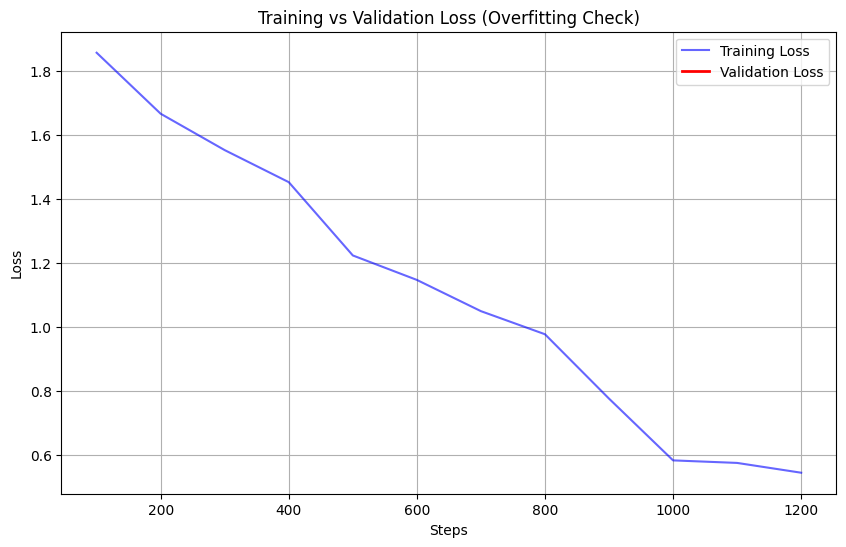

In [ ]:
# Extract logs
log_history = trainer.state.log_history

# Filter data
train_loss = []
train_steps = []
eval_loss = []
eval_steps = []

for entry in log_history:
    if 'loss' in entry:
        train_loss.append(entry['loss'])
        train_steps.append(entry['step'])
    if 'eval_loss' in entry:
        eval_loss.append(entry['eval_loss'])
        eval_steps.append(entry['step'])

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(train_steps, train_loss, label='Training Loss', color='blue', alpha=0.6)
plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', linewidth=2)

plt.xlabel('Steps')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss (Overfitting Check)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(f"💾 Saving Final Model to {output_model_path}...")
trainer.save_model(output_model_path)
tokenizer.save_pretrained(output_model_path)
print("✅ Model Saved Successfully!")

# --- QUICK INFERENCE TEST ---
from transformers import pipeline
translator = pipeline("translation", model=output_model_path, tokenizer=output_model_path, device=0)

# Test Inputs from your dataset style
test_prompts = [
    "Translate eng_Latn to ben_Beng: I am confident.",
    "Translate eng_Latn to mrm_Latn: Don't be shy.",
    "Translate eng_Latn to mrm_Beng: Speak up."
]

print("\n--- Testing Predictions ---")
for prompt in test_prompts:
    # Extract src_lang and tgt_lang from the prompt
    parts = prompt.split(' ')
    src_lang = parts[1]
    tgt_lang = parts[3].replace(':', '')

    # Pass src_lang and tgt_lang to the translator
    res = translator(prompt, max_length=128, src_lang=src_lang, tgt_lang=tgt_lang)
    print(f"Input:  {prompt}")
    print(f"Output: {res[0]['translation_text']}")
    print("-" * 30)


💾 Saving Final Model to /content/drive/MyDrive/Final_NLLB_imperative_Model...
✅ Model Saved Successfully!


The tokenizer you are loading from '/content/drive/MyDrive/Final_NLLB_imperative_Model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Device set to use cuda:0



--- Testing Predictions ---
Input:  Translate eng_Latn to ben_Beng: I am confident.
Output: আমি আত্মবিশ্বাসী।
------------------------------
Input:  Translate eng_Latn to mrm_Latn: Don't be shy.
Output: mashang makrage.
------------------------------
Input:  Translate eng_Latn to mrm_Beng: Speak up.
Output: angcha proh.।
------------------------------


In [ ]:
import evaluate
from tqdm.auto import tqdm
import pandas as pd

# Load Metrics
sacrebleu = evaluate.load("sacrebleu")
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

print("\n--- Running Detailed Evaluation (Per Direction) ---")

# We will group predictions by direction
results_by_dir = {}

model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# Iterate through Test Set
# (For speed, you can limit this. Remove [:2000] to run on ALL 19k rows)
test_subset = test_dataset.select(range(min(2000, len(test_dataset))))

for item in tqdm(test_subset, desc="Evaluating"):
    # Generate
    input_ids = tokenizer(item["input_text"], return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model.generate(input_ids, max_new_tokens=128)

    pred = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
    ref = item["target_text"].strip()
    # Fix: Create 'direction' from existing 'src_lang' and 'tgt_lang'
    direction = f"{item['src_lang']}-{item['tgt_lang']}"

    if direction not in results_by_dir:
        results_by_dir[direction] = {"preds": [], "refs": []}

    results_by_dir[direction]["preds"].append(pred)
    results_by_dir[direction]["refs"].append(ref)

# Compute Scores
final_scores = []

for direction, data in results_by_dir.items():
    preds = data["preds"]
    refs = data["refs"]

    # BLEU
    bleu = sacrebleu.compute(predictions=preds, references=[[r] for r in refs])["score"]

    # WER & CER
    wer = wer_metric.compute(predictions=preds, references=refs)
    cer = cer_metric.compute(predictions=preds, references=refs)

    # Accuracies
    wa = max(0, 1 - wer) * 100  # Word Accuracy %
    ca = max(0, 1 - cer) * 100  # Char Accuracy %

    final_scores.append({
        "Direction": direction,
        "BLEU": bleu,
        "WER": wer,
        "CER": cer,
        "WA (%)": wa,
        "CA (%)": ca,
        "Samples": len(preds)
    })

# Show Table
df_results = pd.DataFrame(final_scores).sort_values("Direction")
print("\n📊 Detailed Scores per Direction:")
print(df_results.to_markdown(index=False))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(



--- Running Detailed Evaluation (Per Direction) ---


Evaluating:   0%|          | 0/2000 [00:00<?, ?it/s]


📊 Detailed Scores per Direction:
| Direction         |    BLEU |      WER |       CER |   WA (%) |   CA (%) |   Samples |
|:------------------|--------:|---------:|----------:|---------:|---------:|----------:|
| ben_Beng-eng_Latn | 68.4762 | 0.246835 | 0.171035  |  75.3165 |  82.8965 |       157 |
| ben_Beng-mrm_Beng | 12.8584 | 0.881356 | 0.530908  |  11.8644 |  46.9092 |       157 |
| ben_Beng-mrm_Latn | 13.9215 | 0.829424 | 0.493303  |  17.0576 |  50.6697 |       157 |
| eng_Latn-ben_Beng | 46.9661 | 0.376289 | 0.223149  |  62.3711 |  77.6851 |       188 |
| eng_Latn-mrm_Beng | 13.8907 | 0.848592 | 0.508025  |  15.1408 |  49.1975 |       188 |
| eng_Latn-mrm_Latn | 13.1441 | 0.819643 | 0.484623  |  18.0357 |  51.5377 |       188 |
| mrm_Beng-ben_Beng | 24.4973 | 0.626667 | 0.462333  |  37.3333 |  53.7667 |       167 |
| mrm_Beng-eng_Latn | 36.3604 | 0.572874 | 0.437158  |  42.7126 |  56.2842 |       167 |
| mrm_Beng-mrm_Latn | 65.9092 | 0.198807 | 0.0571327 |  80.1193 |  94.2867 |

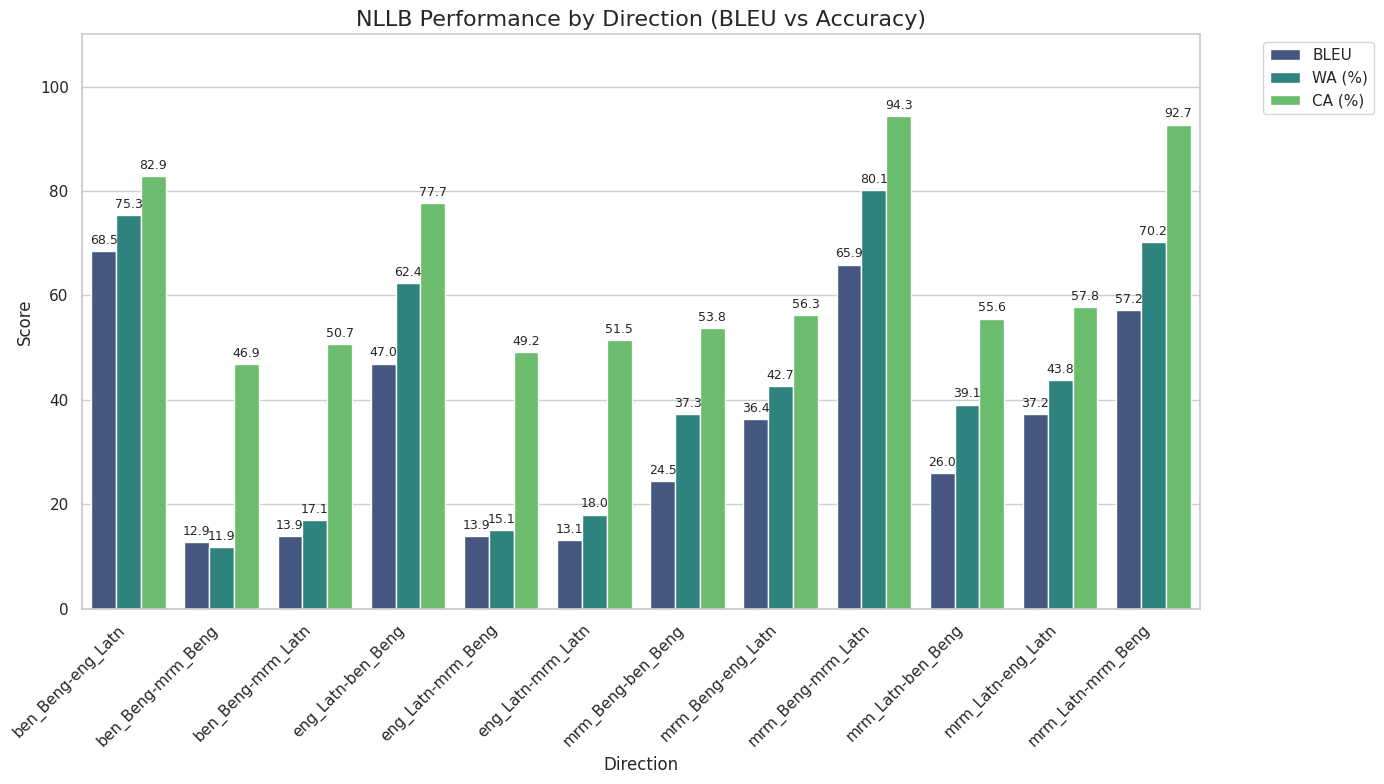

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape for Plotting
df_melt = df_results.melt(id_vars=["Direction"], value_vars=["BLEU", "WA (%)", "CA (%)"],
                          var_name="Metric", value_name="Score")

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Create Bar Plot
chart = sns.barplot(
    data=df_melt,
    x="Direction",
    y="Score",
    hue="Metric",
    palette="viridis"
)

plt.xticks(rotation=45, ha='right')
plt.title("NLLB Performance by Direction (BLEU vs Accuracy)", fontsize=16)
plt.ylim(0, 110)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Add values on bars
for container in chart.containers:
    chart.bar_label(container, fmt='%.1f', padding=3, size=9)

plt.tight_layout()
plt.show()